# A/B Test: Cookie Cats
### Does moving the first gate from level 30 to level 40 affect player retention?

## 1. Context and analysis plan

In *Cookie Cats* (a mobile puzzle game), players hit "gates" that force them to wait or pay to keep playing. This experiment moved the first gate:

- **Control:** `gate_30` (gate at level 30)
- **Treatment:** `gate_40` (gate at level 40)

**Analysis plan, fixed before running the tests** (the dataset is public, so this is a plan, not a formal pre-registration):

| Item | Definition |
|---|---|
| Primary metric | 7-day retention (`retention_7`) |
| Secondary metrics | 1-day retention (`retention_1`) and rounds played (`sum_gamerounds`) |
| H₀ | No difference in retention between groups |
| H₁ | There is a difference in retention between groups (two-sided test) |
| Significance level | α = 0.05 |
| Multiple-comparison correction | Bonferroni (3 metrics → adjusted α = 0.05 / 3 ≈ 0.0167) |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import chisquare, chi2_contingency, ttest_ind, mannwhitneyu
from statsmodels.stats.proportion import proportions_ztest, proportion_effectsize
from statsmodels.stats.power import NormalIndPower

ALPHA = 0.05
N_METRICS = 3
ALPHA_BONF = ALPHA / N_METRICS
plt.rcParams["figure.figsize"] = (8, 4)

## 2. Load the data

In [2]:
# Google Colab: upload the file. Outside Colab, just read the local CSV.
try:
    from google.colab import files
    uploaded = files.upload()
    file_name = list(uploaded.keys())[0]
except ImportError:
    file_name = "cookie_cats.csv"

df = pd.read_csv(file_name)
df.head()

,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 90189 entries, 0 to 90188
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   userid          90189 non-null  int64
 1   version         90189 non-null  str  
 2   sum_gamerounds  90189 non-null  int64
 3   retention_1     90189 non-null  bool 
 4   retention_7     90189 non-null  bool 
dtypes: bool(2), int64(2), str(1)
memory usage: 2.2 MB


## 3. Sanity checks

In [4]:
print("Missing values per column:")
print(df.isna().sum())
print("\nDuplicated users (by userid):", df.duplicated("userid").sum())

Missing values per column:
userid            0
version           0
sum_gamerounds    0
retention_1       0
retention_7       0
dtype: int64

Duplicated users (by userid): 0


In [5]:
group_sizes = df["version"].value_counts().sort_index()
print(group_sizes)
print(f"\ngate_30 share: {group_sizes['gate_30'] / len(df):.4f}")

version
gate_30    44700
gate_40    45489
Name: count, dtype: int64

gate_30 share: 0.4956


### 3.1 Sample Ratio Mismatch (SRM)

If randomization was 50/50, both groups should be close in size. We test this with a chi-square test (H₀: 50/50 split).
A low p-value suggests a problem in how users were assigned to groups. Many experimentation teams only raise an SRM alert
at a stricter threshold (commonly p < 0.001), because with large samples tiny imbalances can reach p < 0.05; we report both levels.

In [6]:
chi2_srm, p_srm = chisquare(group_sizes.values)
print(f"χ² = {chi2_srm:.3f} | p-value = {p_srm:.4f}")
if p_srm < 0.001:
    print("🚨 Strong SRM: p < 0.001. Assignment likely broken; results should not be trusted.")
elif p_srm < ALPHA:
    print("⚠️ Mild/borderline SRM: p < 0.05 but p >= 0.001. Flag as a data-quality caveat and investigate.")
else:
    print("✅ No evidence of SRM.")

χ² = 6.902 | p-value = 0.0086
⚠️ Mild/borderline SRM: p < 0.05 but p >= 0.001. Flag as a data-quality caveat and investigate.


> **Interpretation:** The chi-square test gives p = 0.0086. That is below 0.05 but well above the stricter p < 0.001
> threshold many teams use to trigger an SRM alert, so we classify it as a **mild / borderline** imbalance rather than a
> confirmed assignment failure. The observed split (44,700 vs. 45,489, i.e. 49.56% / 50.44%) is only ~0.9 percentage points
> from even. It is unlikely to drive the retention result on its own, but it is worth flagging as a data-quality caveat.

**Investigating further:** if the imbalance were caused by a hash-based assignment bug, it would likely show up as a pattern
tied to `userid` — e.g. concentrated in a specific id range, or split differently between odd and even ids. We check both.

In [7]:
# Does the imbalance concentrate in a specific userid range?
df["userid_decile"] = pd.qcut(df["userid"], 10, labels=False)
decile_tab = pd.crosstab(df["userid_decile"], df["version"])
decile_tab["gate_30_share"] = decile_tab["gate_30"] / (decile_tab["gate_30"] + decile_tab["gate_40"])
decile_chi2, decile_p, _, _ = chi2_contingency(decile_tab[["gate_30", "gate_40"]])
print(decile_tab)
print(f"\nuserid decile x version interaction: chi2 = {decile_chi2:.3f}, p = {decile_p:.4f}")

version        gate_30  gate_40  gate_30_share
userid_decile                                 
0                 4474     4545       0.496064
1                 4486     4533       0.497394
2                 4507     4512       0.499723
3                 4542     4477       0.503604
4                 4391     4628       0.486861
5                 4471     4547       0.495786
6                 4487     4532       0.497505
7                 4474     4545       0.496064
8                 4450     4569       0.493403
9                 4418     4601       0.489855

userid decile x version interaction: chi2 = 7.308, p = 0.6051


In [8]:
# Is the split different for odd vs. even userid (common symptom of hash-based bucketing bugs)?
df["userid_parity"] = np.where(df["userid"] % 2 == 0, "even", "odd")
parity_tab = pd.crosstab(df["userid_parity"], df["version"])
parity_tab["gate_30_share"] = parity_tab["gate_30"] / (parity_tab["gate_30"] + parity_tab["gate_40"])
print(parity_tab)

parity_chi2, parity_p, _, _ = chi2_contingency(parity_tab[["gate_30", "gate_40"]])
print(f"\nuserid parity x version interaction: chi2 = {parity_chi2:.3f}, p = {parity_p:.4f}")

for label, sub in df.groupby("userid_parity"):
    g = sub["version"].value_counts()
    c2, p_ = chisquare(g.values)
    print(f"  {label} ids alone vs. 50/50: p = {p_:.4f}")

version        gate_30  gate_40  gate_30_share
userid_parity                                 
even             22403    22563       0.498221
odd              22297    22926       0.493046

userid parity x version interaction: chi2 = 2.395, p = 0.1217
  even ids alone vs. 50/50: p = 0.4505
  odd ids alone vs. 50/50: p = 0.0031


**Result of the investigation:** Neither check points to `userid` as the source of the SRM.

- By **decile** of `userid`, the gate_30 share ranges narrowly from 48.7% to 50.4% across the 10 buckets, and the
  interaction test between `userid` decile and `version` is not significant (χ² = 7.31, df = 9, p = 0.605).
- By **odd/even `userid`**, the split is 49.8% (even) vs. 49.3% (odd) gate_30 — closer than the deciles — and the
  interaction test is also not significant (χ² = 2.40, p = 0.122), even though the odd-id subgroup alone deviates
  from a strict 50/50 split a bit more than the even-id subgroup (p = 0.0031 vs. p = 0.45 against 50/50).

So the SRM does **not** concentrate in an identifiable `userid` range or parity group — we find no evidence for the simplest
hash-bucketing explanations (non-significant tests cannot fully rule them out). The cause is more likely upstream of `userid` entirely (assignment timing, platform,
geography, or a different bucketing key altogether), none of which are available in this dataset. The concrete next
step — pulling the actual assignment/bucketing key from the experimentation platform and re-running this same check
on it — is listed in section 12.

## 4. Outliers

In [9]:
df["sum_gamerounds"].describe()

count    90189.000000
mean        51.872457
std        195.050858
min          0.000000
25%          5.000000
50%         16.000000
75%         51.000000
max      49854.000000
Name: sum_gamerounds, dtype: float64

In [10]:
Q1 = df["sum_gamerounds"].quantile(0.25)
Q3 = df["sum_gamerounds"].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
outliers = df[~df["sum_gamerounds"].between(lower_bound, upper_bound)]

print(f"IQR bounds: [{lower_bound:.0f}, {upper_bound:.0f}]")
print(f"Users above the bound: {len(outliers)} ({len(outliers) / len(df):.1%})")
outliers["sum_gamerounds"].describe()

IQR bounds: [-64, 120]
Users above the bound: 10177 (11.3%)


count    10177.000000
mean       271.170581
std        526.338551
min        121.000000
25%        153.000000
50%        204.000000
75%        309.000000
max      49854.000000
Name: sum_gamerounds, dtype: float64

In [11]:
# Top of the distribution: any truly implausible values?
df["sum_gamerounds"].sort_values(ascending=False).head(10)

57702    49854
7912      2961
29417     2640
43671     2438
48188     2294
46344     2251
87007     2156
36933     2124
88328     2063
6536      2015
Name: sum_gamerounds, dtype: int64

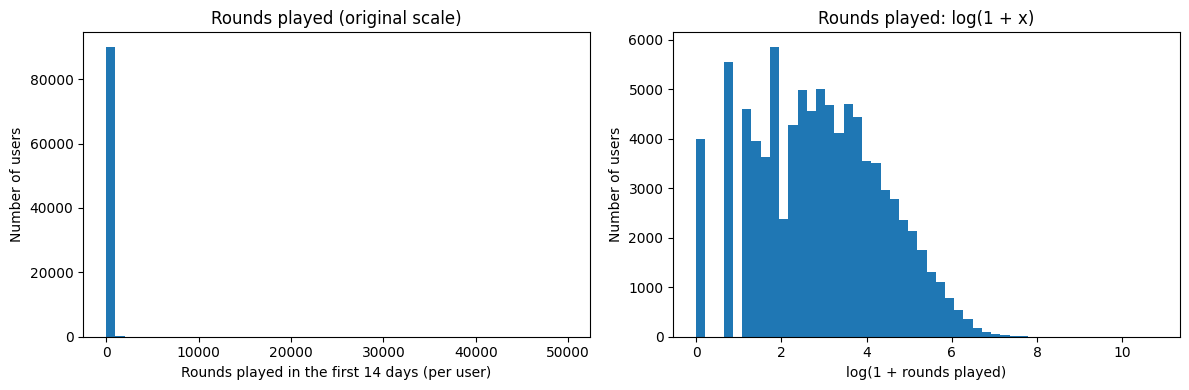

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(df["sum_gamerounds"], bins=50)
ax[0].set_title("Rounds played (original scale)")
ax[0].set_xlabel("Rounds played in the first 14 days (per user)")
ax[0].set_ylabel("Number of users")
ax[1].hist(np.log1p(df["sum_gamerounds"]), bins=50)
ax[1].set_title("Rounds played: log(1 + x)")
ax[1].set_xlabel("log(1 + rounds played)")
ax[1].set_ylabel("Number of users")
plt.tight_layout()
plt.show()

### Decision on outliers

The IQR rule flags a large share of the base (~11%) because the distribution is **heavily right-skewed** (median ≈ 16, mean ≈ 52).
These users are **legitimately engaged players**, not errors; removing them would distort the experiment. **They were kept.**

Only the user with **49,854 rounds** was removed: an isolated value inconsistent with the rest of the data (likely a bot or a logging error).
For the rounds-played metric, we use robust methods (Mann-Whitney, Welch's t-test on log scale, and bootstrap).
For retention metrics (binary), outliers have no effect.

In [13]:
df_clean = df[df["sum_gamerounds"] < 10000].copy()
print(f"Rows removed: {len(df) - len(df_clean)}")
print(f"Final sample: {len(df_clean)} users")

Rows removed: 1
Final sample: 90188 users


## 5. Descriptive analysis

In [14]:
summary = df_clean.groupby("version").agg(
    users=("userid", "count"),
    ret_1=("retention_1", "mean"),
    ret_7=("retention_7", "mean"),
    rounds_mean=("sum_gamerounds", "mean"),
    rounds_median=("sum_gamerounds", "median"),
)
summary.style.format({"ret_1": "{:.2%}", "ret_7": "{:.2%}",
                       "rounds_mean": "{:.2f}", "rounds_median": "{:.0f}"})

,users,ret_1,ret_7,rounds_mean,rounds_median
version,,,,,
gate_30,44699,44.82%,19.02%,51.34,17
gate_40,45489,44.23%,18.20%,51.30,16


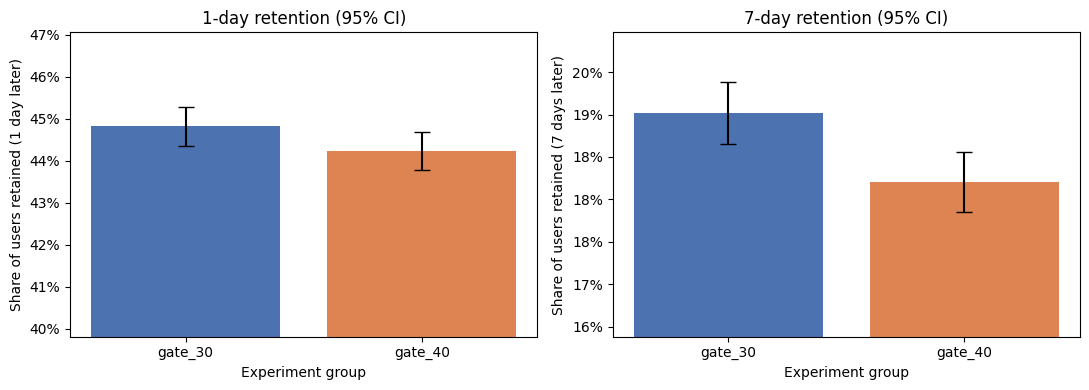

In [15]:
# Retention with 95% confidence interval (normal approximation)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col, title in zip(axes, ["retention_1", "retention_7"], ["1-day retention", "7-day retention"]):
    g = df_clean.groupby("version")[col].agg(["mean", "count"])
    err = 1.96 * np.sqrt(g["mean"] * (1 - g["mean"]) / g["count"])
    ax.bar(g.index, g["mean"], yerr=err, capsize=6, color=["#4C72B0", "#DD8452"])
    ax.set_title(f"{title} (95% CI)")
    ax.set_xlabel("Experiment group")
    ax.set_ylabel(f"Share of users retained ({'1' if col=='retention_1' else '7'} day{'s' if col=='retention_7' else ''} later)")
    ax.set_ylim(g["mean"].min() * 0.9, g["mean"].max() * 1.05)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
plt.tight_layout()
plt.show()

## 6. Hypothesis tests: binary metrics (retention)

We use the **two-proportion z-test** and cross-check with **chi-square**. Beyond the p-value, we report the absolute
difference with a 95% CI, relative lift, and effect size (Cohen's h).

In [16]:
def analyze_retention(col, base=df_clean):
    g = base.groupby("version")[col].agg(["sum", "count"])
    s_a, n_a = g.loc["gate_30", "sum"], g.loc["gate_30", "count"]
    s_b, n_b = g.loc["gate_40", "sum"], g.loc["gate_40", "count"]
    p_a, p_b = s_a / n_a, s_b / n_b

    z, p_z = proportions_ztest([s_a, s_b], [n_a, n_b])
    table = pd.crosstab(base["version"], base[col])
    _, p_chi2, _, _ = chi2_contingency(table, correction=False)

    diff = p_b - p_a  # treatment (gate_40) minus control (gate_30)
    se = np.sqrt(p_a * (1 - p_a) / n_a + p_b * (1 - p_b) / n_b)
    ci = (diff - 1.96 * se, diff + 1.96 * se)

    return {
        "metric": col,
        "rate_gate_30": p_a, "rate_gate_40": p_b,
        "diff_pp": diff * 100,
        "ci95_pp": (ci[0] * 100, ci[1] * 100),
        "relative_lift": diff / p_a,
        "cohens_h": proportion_effectsize(p_b, p_a),
        "p_z": p_z, "p_chi2": p_chi2,
    }

def show(r, alpha=ALPHA_BONF):
    print(f"--- {r['metric']} ---")
    print(f"gate_30: {r['rate_gate_30']:.2%} | gate_40: {r['rate_gate_40']:.2%}")
    print(f"Difference (gate_40 - gate_30): {r['diff_pp']:+.2f} pp "
          f"(95% CI: {r['ci95_pp'][0]:+.2f} to {r['ci95_pp'][1]:+.2f} pp)")
    print(f"Relative lift: {r['relative_lift']:+.2%} | Cohen's h: {r['cohens_h']:+.4f}")
    print(f"p-value (z): {r['p_z']:.4f} | p-value (chi2): {r['p_chi2']:.4f}")
    sig = "SIGNIFICANT" if r["p_z"] < alpha else "not significant"
    print(f"At adjusted α = {alpha:.4f}: {sig}\n")

r7 = analyze_retention("retention_7")
r1 = analyze_retention("retention_1")
show(r7)
show(r1)

--- retention_7 ---
gate_30: 19.02% | gate_40: 18.20%
Difference (gate_40 - gate_30): -0.82 pp (95% CI: -1.33 to -0.31 pp)
Relative lift: -4.30% | Cohen's h: -0.0210
p-value (z): 0.0016 | p-value (chi2): 0.0016
At adjusted α = 0.0167: SIGNIFICANT

--- retention_1 ---
gate_30: 44.82% | gate_40: 44.23%
Difference (gate_40 - gate_30): -0.59 pp (95% CI: -1.24 to +0.06 pp)
Relative lift: -1.32% | Cohen's h: -0.0119
p-value (z): 0.0739 | p-value (chi2): 0.0739
At adjusted α = 0.0167: not significant



## 7. Hypothesis test: continuous metric (rounds played)

The distribution is heavily skewed, so a t-test on raw data is fragile. We use:
1. **Welch's t-test** on `log(1 + rounds)`
2. **Mann-Whitney U** (non-parametric)
3. **Bootstrap** of the mean difference (raw data)

In [17]:
a = df_clean.loc[df_clean["version"] == "gate_30", "sum_gamerounds"].values
b = df_clean.loc[df_clean["version"] == "gate_40", "sum_gamerounds"].values

t_stat, p_t_log = ttest_ind(np.log1p(a), np.log1p(b), equal_var=False)
u_stat, p_mw = mannwhitneyu(a, b, alternative="two-sided")
print(f"Welch (log1p):  p = {p_t_log:.4f}")
print(f"Mann-Whitney:   p = {p_mw:.4f}")
print(f"Mean gate_30 = {a.mean():.2f} | mean gate_40 = {b.mean():.2f}")
print(f"Median gate_30 = {np.median(a):.0f} | median gate_40 = {np.median(b):.0f}")

Welch (log1p):  p = 0.0724
Mann-Whitney:   p = 0.0509
Mean gate_30 = 51.34 | mean gate_40 = 51.30
Median gate_30 = 17 | median gate_40 = 16


Mean difference (gate_40 - gate_30): -0.04 rounds
95% bootstrap CI: [-1.26, +1.35]


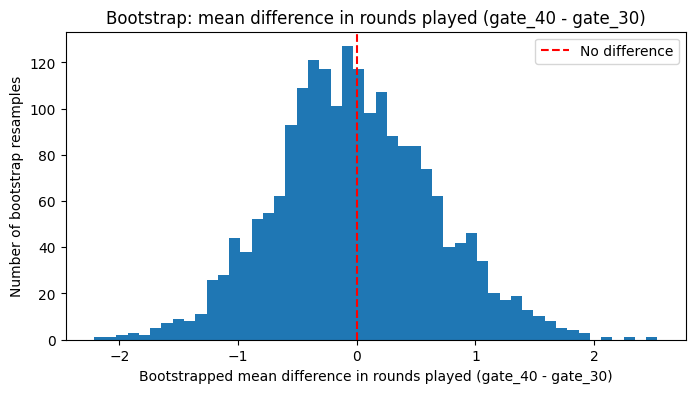

In [18]:
rng = np.random.default_rng(42)
N_BOOT = 2000
diffs = np.empty(N_BOOT)
for i in range(N_BOOT):
    diffs[i] = rng.choice(b, size=len(b)).mean() - rng.choice(a, size=len(a)).mean()

ci_boot = np.percentile(diffs, [2.5, 97.5])
print(f"Mean difference (gate_40 - gate_30): {b.mean() - a.mean():+.2f} rounds")
print(f"95% bootstrap CI: [{ci_boot[0]:+.2f}, {ci_boot[1]:+.2f}]")

plt.hist(diffs, bins=50)
plt.axvline(0, color="red", linestyle="--", label="No difference")
plt.title("Bootstrap: mean difference in rounds played (gate_40 - gate_30)")
plt.xlabel("Bootstrapped mean difference in rounds played (gate_40 - gate_30)")
plt.ylabel("Number of bootstrap resamples")
plt.legend()
plt.show()

## 8. Bootstrap for 7-day retention

Confirms the z-test result without relying on the normal approximation.

In [19]:
r7_a = df_clean.loc[df_clean["version"] == "gate_30", "retention_7"].values.astype(int)
r7_b = df_clean.loc[df_clean["version"] == "gate_40", "retention_7"].values.astype(int)

boot_ret = np.empty(N_BOOT)
for i in range(N_BOOT):
    boot_ret[i] = rng.choice(r7_b, size=len(r7_b)).mean() - rng.choice(r7_a, size=len(r7_a)).mean()

ci_ret = np.percentile(boot_ret, [2.5, 97.5]) * 100
print(f"95% bootstrap CI for the 7-day retention difference: [{ci_ret[0]:+.2f}, {ci_ret[1]:+.2f}] pp")
print(f"Share of resamples with difference >= 0: {(boot_ret >= 0).mean():.4f}")

95% bootstrap CI for the 7-day retention difference: [-1.33, -0.34] pp
Share of resamples with difference >= 0: 0.0005


## 9. Statistical power and sample size

In [20]:
p_base = r7["rate_gate_30"]
n_per_group = df_clean["version"].value_counts().min()

# (a) Minimum detectable effect (MDE) with 80% power, given the current sample size
h_min = NormalIndPower().solve_power(nobs1=n_per_group, alpha=ALPHA, power=0.8, ratio=1.0)
print(f"Minimum detectable effect (Cohen's h) with n={n_per_group} per group, 80% power: {h_min:.4f}")
print(f"Observed |Cohen's h| for 7-day retention: {abs(r7['cohens_h']):.4f}")

# (b) Sample size needed to detect a 1 pp drop in 7-day retention
effect_1pp = proportion_effectsize(p_base - 0.01, p_base)
n_needed = NormalIndPower().solve_power(effect_size=abs(effect_1pp), alpha=ALPHA, power=0.8)
print(f"Sample size per group needed to detect 1 pp: {int(np.ceil(n_needed))}")

# Note: "observed power" is deliberately not reported. It is a direct function of the p-value
# and adds no information; the MDE above is the defensible way to judge sensitivity.

Minimum detectable effect (Cohen's h) with n=44699 per group, 80% power: 0.0187
Observed |Cohen's h| for 7-day retention: 0.0210
Sample size per group needed to detect 1 pp: 23683


## 10. Results summary

In [21]:
final_summary = pd.DataFrame([
    {"Metric": "1-day retention", "gate_30": f"{r1['rate_gate_30']:.2%}", "gate_40": f"{r1['rate_gate_40']:.2%}",
     "Difference": f"{r1['diff_pp']:+.2f} pp", "p-value": round(r1["p_z"], 4),
     "Significant (Bonferroni)": r1["p_z"] < ALPHA_BONF},
    {"Metric": "7-day retention", "gate_30": f"{r7['rate_gate_30']:.2%}", "gate_40": f"{r7['rate_gate_40']:.2%}",
     "Difference": f"{r7['diff_pp']:+.2f} pp", "p-value": round(r7["p_z"], 4),
     "Significant (Bonferroni)": r7["p_z"] < ALPHA_BONF},
    {"Metric": "Rounds played (Mann-Whitney)", "gate_30": f"{a.mean():.1f} (mean)", "gate_40": f"{b.mean():.1f} (mean)",
     "Difference": f"{b.mean() - a.mean():+.2f} rounds", "p-value": round(p_mw, 4),
     "Significant (Bonferroni)": p_mw < ALPHA_BONF},
])
final_summary

,Metric,gate_30,gate_40,Difference,p-value,Significant (Bonferroni)
0,1-day retention,44.82%,44.23%,-0.59 pp,0.0739,False
1,7-day retention,19.02%,18.20%,-0.82 pp,0.0016,True
2,Rounds played (Mann-Whitney),51.3 (mean),51.3 (mean),-0.04 rounds,0.0509,False


## 11. Conclusion and business recommendation

7-day retention was **19.02%** for gate_30 and **18.20%** for gate_40, a difference of **-0.82 pp**
(95% CI: -1.33 to -0.31 pp; p = 0.0016, bootstrap CI: -1.33 to -0.34 pp). This result is statistically significant even
after Bonferroni correction (adjusted α = 0.0167), and three methods (z-test, chi-square, bootstrap) agree on direction and magnitude.

The effect is small: a **-4.3% relative lift** (Cohen's h = -0.021). For sensitivity, the minimum detectable effect at 80% power
with ~44,700 users per group is h ≈ 0.0187, so the observed effect sits just above what this experiment could reliably detect.
The confidence interval is also fairly wide relative to the estimate (-1.33 to -0.31 pp), so the true effect could be
considerably smaller or larger than -0.82 pp.

1-day retention was **44.82%** vs. **44.23%** (-0.59 pp, p = 0.074): same direction, but **not significant** at the adjusted threshold.
For rounds played there is **no evidence of a difference** (means 51.34 vs. 51.30; Mann-Whitney p = 0.051, borderline; Welch on log scale p = 0.072).
So the data point to a drop in players coming back after the first week, not to a change in how much they play overall.

**Possible explanation (hypothesis, not tested here):** the forced pause at level 30 may prevent early over-consumption of content,
so postponing it to level 40 removes that pause and some players churn instead. This dataset has no information on
player behavior around the gate, so it cannot confirm or refute this idea.

**Recommendation: keep the gate at level 30.** Moving the gate to level 40 is associated with lower 7-day retention, and nothing
in this data (rounds played, D1 retention) suggests an offsetting benefit. The practical effect is modest, and revenue impact
is unmeasured, so this is a "do not switch" recommendation based on available evidence, not proof that level 30 is optimal.

**Caveats:** the mild SRM in section 3.1, the short 7-day horizon, and the lack of revenue data (see section 12). The recommendation
should be validated with a longer or re-randomized follow-up experiment before being treated as final.

## 12. Limitations and next steps

- **SRM (mild):** the group split deviates from 50/50 at p = 0.0086 (see section 3.1). The follow-up checks on `userid` range and
  odd/even `userid` found no evidence that the imbalance is tied to `userid`. **Concrete next step:** obtain the assignment log
  (or ask the experimentation/engineering team) for the actual bucketing key — e.g. device ID, session ID, install timestamp — and
  rerun the same decile/parity interaction test on *that* key, since `userid` may not be the field the randomizer hashed on.
- **Short time horizon:** retention was measured only up to D7. Long-term retention (D30+) and **revenue** (in-app purchases, ads) are unknown.
- **Sensitivity:** the observed effect (h = 0.021) is close to the minimum detectable effect (h = 0.0187), and the CI is wide. A larger
  or longer experiment would tighten the estimate.
- **Novelty effect:** behavior in the first days may not reflect steady-state behavior.
- **No segmentation:** the effect may vary by player profile (new vs. veteran, platform, country).
- **Next steps:** test a gate at another level (e.g., 35 or 50), measure revenue per user, and segment the analysis.